# Лабораторная работа № 4. Свёрточные нейронные сети (CNN)

## ( “Нейросетевые технологии обработки данных”)

### студентки 4-го курса 10-ой группы

### Ярмош Алеси

### Вариант 13

круг, квадрат на изображении 32 × 32, число фильтров: слой 1 - 8, слой 2 - 16

## Постановка задачи

Реализовать на PyTorch (nn.Conv2d, nn.MaxPool2d) свёрточную нейронную сеть для
классификации синтетических изображений простых геометрических фигур согласно варианту задания. Изображения генерировать программно на NumPy (шумный фон + контур фигуры со случайным положением/размером), без использования готовых датасетов
изображений (MNIST, CIFAR и т.п.).

In [134]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import random
from sklearn.metrics import accuracy_score, confusion_matrix

In [135]:
torch.manual_seed(0)
np.random.seed(0)

In [136]:
IMG_SIZE = 32
N_PER_CLASS = 100
CLASSES = ['circle', 'square']
N_CLASSES = len(CLASSES)

In [137]:
def draw_circle(img, cx, cy, r):
    yy, xx = np.mgrid[0:img.shape[0], 0:img.shape[1]]
    mask = np.abs((xx - cx) ** 2 + (yy - cy) ** 2 - r ** 2) < (2.2 * r)
    img[mask] = 1.0
    
def draw_square(img, cx, cy, s):
    half = s // 2
    x0, x1 = max(cx - half, 0), min(cx + half, img.shape[1] - 1)
    y0, y1 = max(cy - half, 0), min(cy + half, img.shape[0] - 1)
    img[y0:y1 + 1, x0] = 1.0
    img[y0:y1 + 1, x1] = 1.0
    img[y0, x0:x1 + 1] = 1.0
    img[y1, x0:x1 + 1] = 1.0

def gen_image(cls):
    img = np.random.normal(0, 0.15, (IMG_SIZE, IMG_SIZE)).astype(np.float32)
    cx = np.random.randint(IMG_SIZE // 4, 3 * IMG_SIZE // 4)
    cy = np.random.randint(IMG_SIZE // 4, 3 * IMG_SIZE // 4)
    if cls == 'circle':
        draw_circle(img, cx, cy, np.random.randint(4, 8))
    elif cls == 'square':
        draw_square(img, cx, cy, np.random.randint(8, 14))
    return np.clip(img, 0, 1)

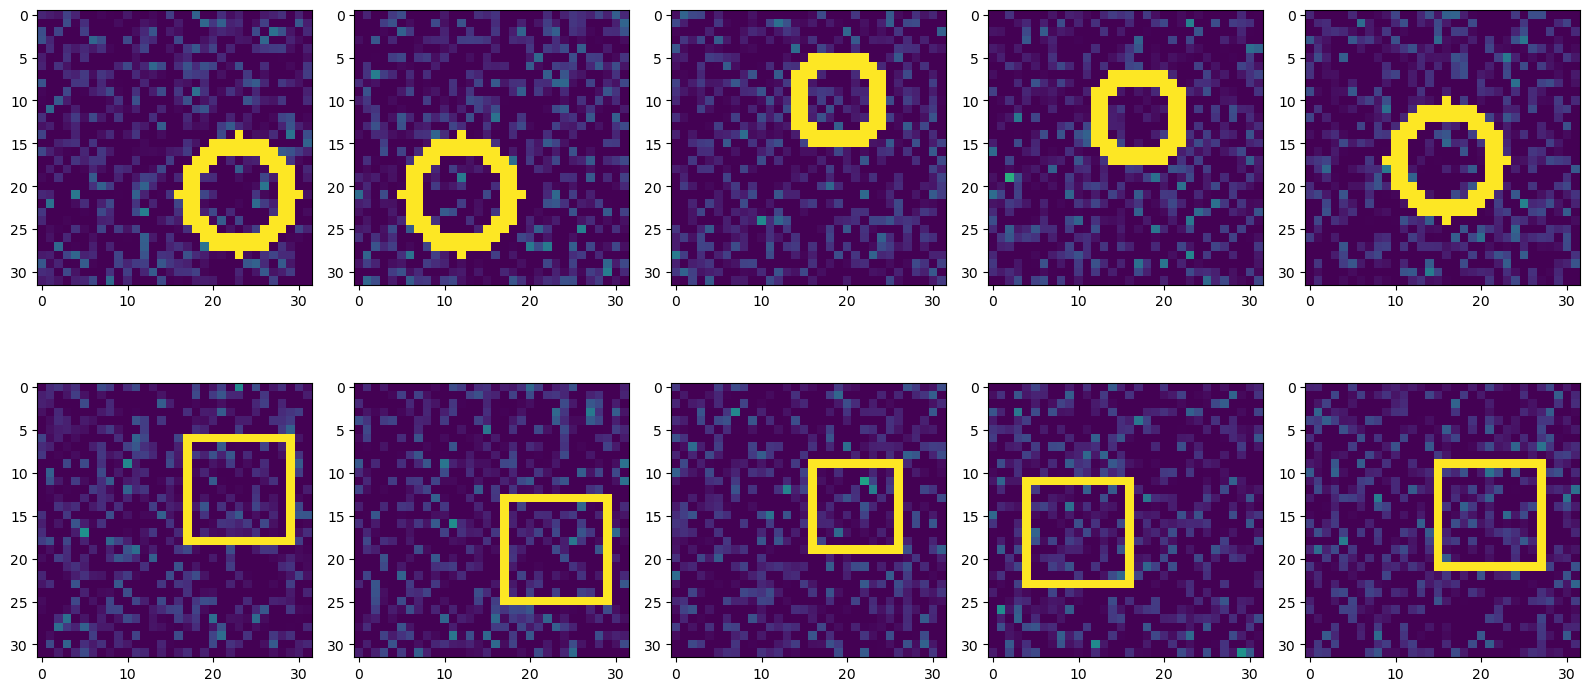

In [138]:
X, y = [], []
n_examples = 5
for ci, cls in enumerate(CLASSES):
    for _ in range(N_PER_CLASS):
        X.append(gen_image(cls))
        y.append(ci)
        
fig, axs = plt.subplots(2, 5, figsize=(16, 8))

for i, im in enumerate(random.sample(X[:N_PER_CLASS], n_examples)):
    axs[0, i].imshow(im)

for i, im in enumerate(random.sample(X[N_PER_CLASS:], n_examples)):
    axs[1, i].imshow(im)

plt.tight_layout()
plt.show()

X = np.array(X, dtype=np.float32)[:, None, :, :] # (N, 1, H, W)
y = np.array(y, dtype=np.int64)
idx = np.random.permutation(len(X))
X, y = X[idx], y[idx]

1.6. Визуализация карт признаков
После обучения полезно пропустить одно тестовое изображение через первый свёрточный слой и визуализировать полученные карты признаков (plt.imshow для каждого
канала выхода conv1) – это наглядно показывает, что уже первый слой сети выучивается
реагировать на края фигуры и границы контраста с фоном.

In [139]:
idx = np.random.permutation(len(X))
X, y = X[idx], y[idx]
n_train = int(0.8 * len(X))
X_train, y_train = X[:n_train], y[:n_train]
X_test, y_test = X[n_train:], y[n_train:]

print(f'Размер обучающей выборки: {len(X_train)}')
print(f'Размер тестовой выборки: {len(X_test)}')

Xtr, ytr = torch.tensor(X_train), torch.tensor(y_train)
Xte, yte = torch.tensor(X_test), torch.tensor(y_test)

Размер обучающей выборки: 160
Размер тестовой выборки: 40


In [ ]:
# 2. Архитектура: Conv(1->8) -> ReLU -> Pool -> Conv(8->16) -> ReLU -> Pool -> FC(32) -> ReLU -> FC(2)
class SimpleCNN(nn.Module):
    def __init__(self, n_classes=4, f1=8, f2=16, img_size=20):
        super().__init__()
        self.conv1 = nn.Conv2d(1, f1, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(f1, f2, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        out_size = img_size // 4
        self.fc1 = nn.Linear(f2 * out_size * out_size, 32)
        self.fc2 = nn.Linear(32, n_classes)
        self.relu = nn.ReLU()
        
    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.flatten(1)
        x = self.relu(self.fc1(x))
        return self.fc2(x)
    
model = SimpleCNN(n_classes=N_CLASSES)
print('Число обучаемых параметров:', sum(p.numel() for p in model.parameters()))

Число обучаемых параметров: 14146


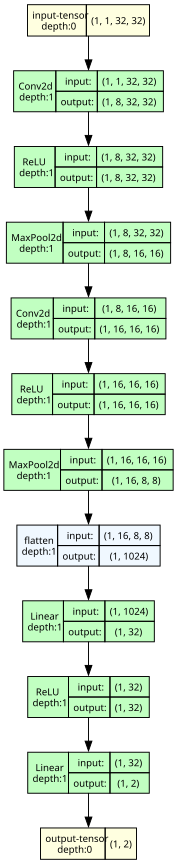

In [141]:
from torchview import draw_graph

model = SimpleCNN(n_classes=N_CLASSES, img_size=IMG_SIZE)

model_graph = draw_graph(
    model,
    input_size=(1, 1, IMG_SIZE, IMG_SIZE),  # batch, channels, height, width
    graph_name="SimpleCNN",
    expand_nested=True
)

model_graph.visual_graph

In [142]:
# 3. Обучение
opt = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()
batch_size, n_epochs = 32, 30
loss_hist, acc_hist = [], []
for epoch in range(n_epochs):
    perm = torch.randperm(len(Xtr))
    total_loss = 0
    for i in range(0, len(Xtr), batch_size):
        b = perm[i:i + batch_size]
        opt.zero_grad()
        out = model(Xtr[b])
        loss = loss_fn(out, ytr[b])
        loss.backward()
        opt.step()
        total_loss += loss.item() * len(b)
    total_loss /= len(Xtr)
    loss_hist.append(total_loss)
    with torch.no_grad():
        pred = model(Xte).argmax(dim=1).numpy()
        acc = accuracy_score(yte, pred)
    acc_hist.append(acc)
    print(confusion_matrix(y_test, pred))
print(f'Итоговая точность на тестовой выборке: {acc_hist[-1]:.4f}')


[[21  0]
 [19  0]]
[[ 5 16]
 [ 0 19]]
[[16  5]
 [ 0 19]]
[[19  2]
 [ 2 17]]
[[18  3]
 [ 0 19]]
[[19  2]
 [ 0 19]]
[[18  3]
 [ 0 19]]
[[20  1]
 [ 0 19]]
[[18  3]
 [ 0 19]]
[[19  2]
 [ 0 19]]
[[19  2]
 [ 0 19]]
[[20  1]
 [ 0 19]]
[[20  1]
 [ 0 19]]
[[20  1]
 [ 0 19]]
[[20  1]
 [ 0 19]]
[[20  1]
 [ 0 19]]
[[20  1]
 [ 0 19]]
[[20  1]
 [ 0 19]]
[[20  1]
 [ 0 19]]
[[20  1]
 [ 0 19]]
[[20  1]
 [ 0 19]]
[[20  1]
 [ 0 19]]
[[20  1]
 [ 0 19]]
[[20  1]
 [ 0 19]]
[[20  1]
 [ 0 19]]
[[20  1]
 [ 0 19]]
[[20  1]
 [ 0 19]]
[[20  1]
 [ 0 19]]
[[20  1]
 [ 0 19]]
[[20  1]
 [ 0 19]]
Итоговая точность на тестовой выборке: 0.9750


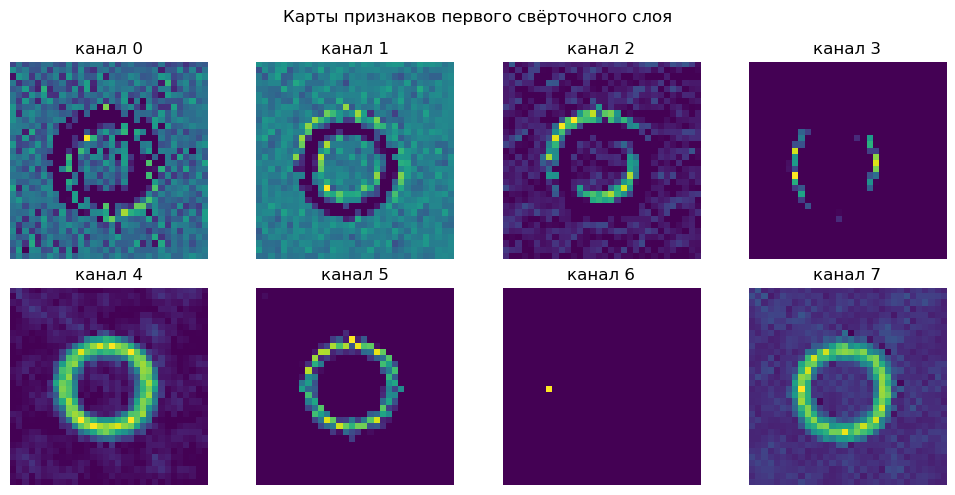

In [143]:
with torch.no_grad():
    example = Xte[:1]
    fmap1 = model.relu(model.conv1(example)) # (1, 8, 20, 20)
    
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(fmap1[0, i].numpy(), cmap='viridis')
    ax.set_title(f'канал {i}')
    ax.axis('off')
plt.suptitle('Карты признаков первого свёрточного слоя')
plt.tight_layout()
plt.show()

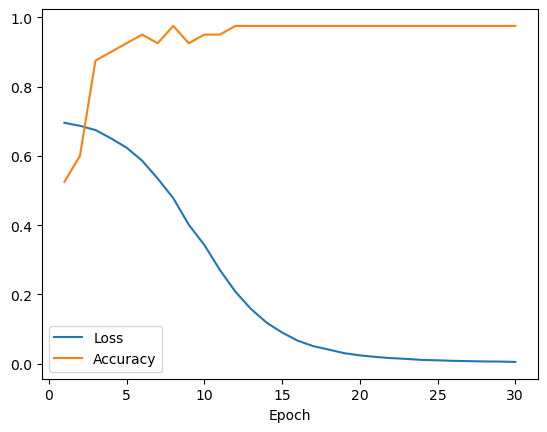

In [144]:
plt.plot(range(1, n_epochs + 1), loss_hist, label='Loss')
plt.plot(range(1, n_epochs + 1), acc_hist, label='Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.show()

Постройте график зависимости точности на тестовой выборке от числа фильтров первого свёрточного слоя f1 ∈ {2, 4, 8, 16, 32} (при фиксированном f2 = 2f1 и фиксированном
достаточно большом числе эпох). Прокомментируйте, начиная с какого числа фильтров
дальнейшее увеличение перестаёт заметно улучшать точность, и объясните этот эффект с
точки зрения сложности решаемой задачи (число различимых классов фигур существенно
меньше числа фильтров, которые способна выучить сеть).

Фильтров на первом слое 2, Итоговая точность на тестовой выборке: 0.975
Фильтров на первом слое 4, Итоговая точность на тестовой выборке: 1.0
Фильтров на первом слое 8, Итоговая точность на тестовой выборке: 1.0
Фильтров на первом слое 16, Итоговая точность на тестовой выборке: 1.0
Фильтров на первом слое 32, Итоговая точность на тестовой выборке: 0.975


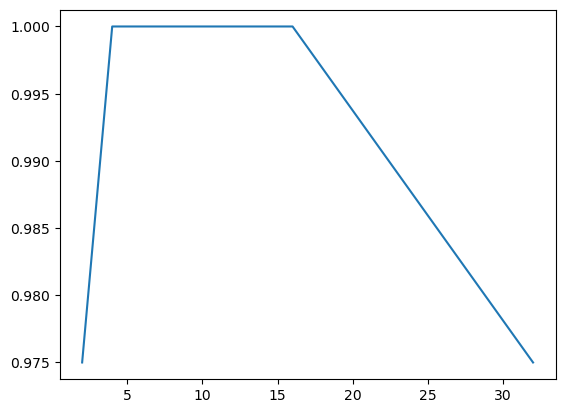

In [ ]:
F1 = (2, 4, 8, 16, 32)
f1_acc = []

for f1 in F1:
    model = SimpleCNN(n_classes=N_CLASSES, img_size=IMG_SIZE, f1=f1)
    opt = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_fn = nn.CrossEntropyLoss()
    batch_size, n_epochs = 32, 30
    loss_hist, acc_hist = [], []
    for epoch in range(n_epochs):
        perm = torch.randperm(len(Xtr))
        total_loss = 0
        for i in range(0, len(Xtr), batch_size):
            b = perm[i:i + batch_size]
            opt.zero_grad()
            out = model(Xtr[b])
            loss = loss_fn(out, ytr[b])
            loss.backward()
            opt.step()
            total_loss += loss.item() * len(b)
        total_loss /= len(Xtr)
        loss_hist.append(total_loss)
    with torch.no_grad():
        pred = model(Xte).argmax(dim=1).numpy()
    acc = accuracy_score(yte, pred)
    f1_acc.append(acc)
    print(f'Фильтров на первом слое {f1}, Итоговая точность на тестовой выборке: {acc}')

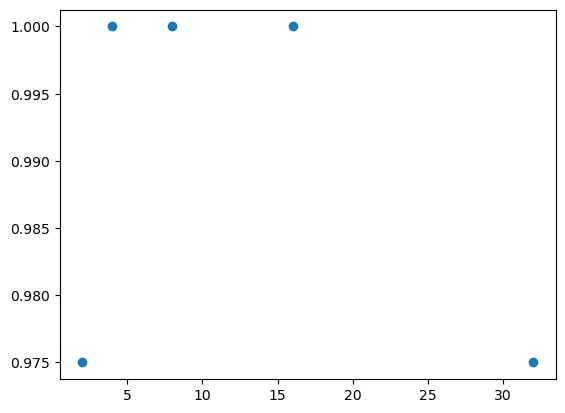

In [146]:
plt.scatter(F1, f1_acc)
plt.show()

## Контрольные вопросы к защите лабораторной работы
### 1. Почему для классификации изображений CNN эффективнее полносвязной сети? Приведите числовое сравнение параметров

    У нас в сети 4 слоя. Предположим вместо каждого слоя мы бы использовали обычный полносвязный слой с таким же числом параметров. Получается:

    Слой 1: изображение 
        32
        ×
        32
        =
        1024
        32×32=1024 входных значения.

    Слой 2: 
        16
        ×
        16
        =
        256
        16×16=256 нейронов.

    Слой 3: 1024 нейрона.

    Слой 4: 32 нейрона.
    
    Итого P=558368 параметров.

    У нашей сети со сверточными слоями получилось 14146 параметров.
​
### 2. Что вычисляет операция свёртки (Conv2d)? Что такое ядро (фильтр), шаг (stride) и дополнение нулями (padding)?

    Операция свертки вычисляет сумму перемноженных элементов исходного изображения и ядра (фильтра) и добавляет смещение. 

    Ядро (фильтр) — это небольшая матрица обучаемых весов, которая перемещается по изображению и анализирует локальные участки. Например, ядро размером 3×3 обрабатывает девять пикселей за один раз. В процессе обучения значения весов ядра изменяются, благодаря чему фильтр учится обнаруживать определённые признаки: границы, линии, текстуры и другие характерные элементы изображения. 

    Шаг -- это расстояние, на которое ядро смещается за одну итерацию в пикселях.

    Padding -- это дополнение нулями изображение, сделанное с целью управления размером выходной карты признаков, т.к. фильтры часто обрезаются при наложении на края изображения.

### 3. По какой формуле вычисляется размер выходной карты признаков? Как padding=1 при ядре 3 × 3 влияет на размер карты?

    Wout = (W − F + 2P) / S + 1 
    
    padding=1 при ядре 3 × 3 возвращает карту признаков размера, эквивалентного исходному изображению.

### 4. Зачем нужен слой подвыборки (MaxPooling)? Чем он отличается от свёрточного слоя по числу обучаемых параметров?

    Он нужен для уменьшения числа обучаемых параметров, увеличения рецептивного поля для последующих слоев и повышения инвариантности модели к небольшим сдвигам объекта.

### 5. Как устроена визуализация карт признаков и что она позволяет понять о работе обученной сети?

    Чтобы визуализировать карты признаков, нужно получить выход одного из слоев модели на изображении. Оттенок пикселя соответствует величине активации нейрона. Таким образом можно отследить, на какие участки изоражения реагирует сеть сильнее и где находит закономерности.